# Rent vs income: bridging suburbs to SA2s

**Goal:** put rent and income side by side. Rent is reported by *rent
area* (a suburb, or a group of suburbs). Income is reported by *SA2*.
These boundaries do not line up, so we need a bridge.

**Chain:** rent area -> suburbs -> SA2s -> income

## What "blended income" means

A mesh block is the smallest ABS unit and sits inside exactly one suburb
and one SA2. We use mesh blocks to measure how much of each rent area's
land falls in each SA2. SA2 incomes are then averaged using those land
areas as weights:

    blended income = sum(area in SA2 x SA2 income) / sum(area in SA2)

**Example.** Yarraville-Seddon covers 6 sq km: 5 sq km in SA2 A (income
60,000) and 1 sq km in SA2 B (income 40,000).
Blended income = (5 x 60,000 + 1 x 40,000) / 6 = 56,667.

**Rules**

- **One rent area, many suburbs:** the suburbs are pooled into one block
  of land, giving one blended income per rent area per year.
- **Two rent areas sharing a suburb:** each area is blended from its own
  set of suburbs. They get the same income only if their suburb sets are
  identical; if the sets merely overlap, the incomes are similar but not
  equal. The checks in section 6 list any shared suburbs.

**Limitations**

- Land area stands in for population, so a sparsely populated corner of
  an SA2 counts as much as a dense one of the same size.
- A weighted average of medians is an approximation, not a true median.
- Income is a per-person median, not household income, so
  `rent_to_income` is a rough affordability indicator.

## 1. Setup and config

Every path, column name and setting lives in this one cell.

In [1]:
import re
from difflib import SequenceMatcher
from pathlib import Path

import pandas as pd

# --- File paths --------------------------------------------------------
MESHBLOCK_FILE = Path("../external_data/MB_2021_AUST.xlsx")
SUBURB_FILE = Path("../external_data/SAL_2021_AUST.xlsx")
INCOME_FILE = Path("../external_data/abs_total_income_sa2_vic_clean.csv")
RENT_FILE = Path("../external_data/rent_by_qtr_suburb_refactored.csv")
OUTPUT_FILE = Path("../external_data/rent_vs_income.csv")

# --- Forecast rent file (June 2026, from the R model) ------------------
FORECAST_FILE = Path("../external_data/2026_rents_forecast_EOFY.csv")
FORECAST_AREA_COL = "Suburb"
FORECAST_RENT_COL = "Forecast_Jun2026"

AFFORDABILITY_2026_FILE = Path("../external_data/2026_affordability.csv")

# --- ABS column names --------------------------------------------------
MB_CODE = "MB_CODE_2021"
AREA_COL = "AREA_ALBERS_SQKM"
SA2_CODE = "SA2_CODE_2021"
SA2_NAME = "SA2_NAME_2021"
SUBURB_NAME = "SAL_NAME_2021"
STATE_COL = "STATE_NAME_2021"

# --- Income file column names ------------------------------------------
INCOME_SA2_COL = "code"
INCOME_COL = "median_total_income_excl_government_pensions_and_allowances_"
YEAR_COL = "year"

# --- Rent file column names (wide: one column per quarter) -------------
RENT_AREA_COL = "Suburb"
QUARTER_COL = "quarter"
RENT_COL = "median_rent"

# --- Rent area -> suburb map column names ------------------------------
MAP_RENT_AREA_COL = RENT_AREA_COL
MAP_SUBURB_COL = "suburb"

# --- Settings ----------------------------------------------------------
WEEKS_PER_YEAR = 52
ABBREVIATIONS = {
    r"\bmt\b": "mount",
    r"\bnth\b": "north",
    r"\bsth\b": "south",
}
EOFY_MONTH = 6  # Income is as at 30 June, so only June quarters are kept.

ACCEPT_SCORE = 1.0  # auto-accept only perfect, untied matches
REVIEW_SCORE = 0.8  # show near matches at or above this for review

# --- Map inputs and outputs --------------------------------------------
# --- Map inputs and outputs --------------------------------------------
SHAPE_FILE = Path(
    "../external_data/SAL_2021_AUST_GDA2020_SHP/SAL_2021_AUST_GDA2020.shp"
)
 # shapefile column names are cut to 10 characters
SHAPE_NAME_COL = "SAL_NAME21"  
SHAPE_STATE_COL = "STE_NAME21"
MELBOURNE_IMAGE_FILE = Path("../Figures/affordability_map_melbourne.png")

## 2. Load the two mesh block files

Codes are read as strings so leading zeros are never lost. The mesh
block file covers all of Australia; the suburb file is filtered to
Victoria.

In [2]:
def read_table(path, **kwargs):
    """Read a CSV or Excel file based on its extension."""
    if path.suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(path, **kwargs)
    return pd.read_csv(path, **kwargs)


mesh = read_table(
    MESHBLOCK_FILE,
    dtype={MB_CODE: str, SA2_CODE: str},
    usecols=[MB_CODE, SA2_CODE, SA2_NAME, AREA_COL],
)
suburbs = read_table(
    SUBURB_FILE,
    dtype={MB_CODE: str},
    usecols=[MB_CODE, SUBURB_NAME, STATE_COL, AREA_COL],
)
suburbs = suburbs[suburbs[STATE_COL] == "Victoria"]

print(f"Mesh blocks (SA2 file, all of Australia): {len(mesh):,}")
print(f"Mesh blocks (suburb file, Victoria only): {len(suburbs):,}")

Mesh blocks (SA2 file, all of Australia): 368,286
Mesh blocks (suburb file, Victoria only): 88,739


## 3. Line them up on the mesh block code

Each mesh block now carries both a suburb and an SA2. The inner join
keeps only mesh blocks present in both files. The mesh block file is
national, so the "dropped from SA2 file" count is simply the
non-Victorian blocks. The count that matters is "dropped from suburb
file", which should be 0.

In [3]:
mb = mesh.merge(
    suburbs,
    on=MB_CODE,
    how="inner",
    suffixes=("", "_sub"),
    validate="one_to_one",
)

print(f"Joined: {len(mb):,} mesh blocks")
print(f"Dropped from SA2 file (non-Victorian): {len(mesh) - len(mb):,}")
print(f"Dropped from suburb file: {len(suburbs) - len(mb):,}")

# Both files describe the same mesh blocks, so areas should be identical.
area_gap = (mb[AREA_COL] - mb[f"{AREA_COL}_sub"]).abs()
print(f"Max area disagreement (sq km): {area_gap.max():.6f}")

Joined: 88,739 mesh blocks
Dropped from SA2 file (non-Victorian): 279,547
Dropped from suburb file: 0
Max area disagreement (sq km): 0.000000


## 4. Suburb -> SA2 area weights

For each suburb, add up mesh block area within each SA2. Dividing by
the suburb's total gives the share of the suburb in each SA2, for
example "Alphington is 52% in SA2 A and 48% in SA2 B". Placeholder
entries with no land area (e.g. "No usual address") are dropped.

In [4]:
# Total mesh block area for each suburb / SA2 pairing.
overlap = (
    mb.groupby([SUBURB_NAME, SA2_CODE, SA2_NAME], as_index=False)[AREA_COL]
    .sum()
    .rename(columns={AREA_COL: "overlap_area"})
)

# Drop placeholder suburbs with no land area (e.g. "No usual address").
suburb_total = overlap.groupby(SUBURB_NAME)["overlap_area"].transform("sum")
overlap = overlap[suburb_total > 0].copy()

# Weight = share of the suburb's area that sits in each SA2.
suburb_total = overlap.groupby(SUBURB_NAME)["overlap_area"].transform("sum")
overlap["weight"] = overlap["overlap_area"] / suburb_total

# Every suburb's weights should sum to 1.
weight_sums = overlap.groupby(SUBURB_NAME)["weight"].sum()
off_target = weight_sums[(weight_sums - 1).abs() > 1e-9]
print(f"Suburbs with weights not summing to 1: {len(off_target)}")

overlap.sort_values(
    [SUBURB_NAME, "weight"], ascending=[True, False]
).head(10)

Suburbs with weights not summing to 1: 0


,SAL_NAME_2021,SA2_CODE_2021,SA2_NAME_2021,overlap_area,weight
0,Abbeyard,204031069,Bright - Mount Beauty,327.5008,1.0
1,Abbotsford (Vic.),206071139,Abbotsford,1.7405,1.0
2,Aberfeldie,206031501,Essendon (West) - Aberfeldie,1.5515,1.0
3,Aberfeldy,205011077,Mount Baw Baw Region,10.8319,1.0
4,Acheron,204011054,Alexandra,72.6602,1.0
5,Ada,205011077,Mount Baw Baw Region,61.6697,1.0
6,Adams Estate,205031093,Wonthaggi - Inverloch,0.2154,1.0
7,Addington,201021010,Creswick - Clunes,18.5958,1.0
8,Adelaide Lead,201031017,Maryborough Surrounds,38.5026,1.0
9,Agnes,205031087,Foster,15.7167,1.0


## 5. Load SA2 income and check coverage

The income file has one row per SA2 per year, so the year is kept and
income is blended separately for each year. Rows with a blank income are
dropped. The table below lists any suburb whose SA2 has no income at
all; the blend skips those SA2s and re-normalises the remaining areas.

In [5]:
income = read_table(INCOME_FILE, dtype={INCOME_SA2_COL: str})
income = income[[INCOME_SA2_COL, YEAR_COL, INCOME_COL]]

# A blank income would shrink the numerator but not the denominator of
# the blend later, so drop blanks now.
income = income.dropna(subset=[INCOME_COL])

no_income = overlap.loc[
    ~overlap[SA2_CODE].isin(income[INCOME_SA2_COL]),
    [SUBURB_NAME, SA2_CODE, SA2_NAME, "overlap_area", "weight"],
]

years = sorted(int(y) for y in income[YEAR_COL].unique())
print(f"Years in income file: {years}")
print(f"SA2s with no income data: {no_income[SA2_CODE].nunique()}")
no_income.sort_values("overlap_area", ascending=False)

Years in income file: [2019, 2020, 2021, 2022, 2023]
SA2s with no income data: 1


,SAL_NAME_2021,SA2_CODE_2021,SA2_NAME_2021,overlap_area,weight
334,Boole Poole,205021083,Lake King,66.6464,0.701820
990,East Bairnsdale,205021083,Lake King,15.7370,0.428800
1988,Metung,205021083,Lake King,5.1379,0.186103
2304,Nicholson (Vic.),205021083,Lake King,3.4017,0.049836
2556,Raymond Island,205021083,Lake King,2.9514,0.119057


## 6. Match rent areas to ABS suburbs

The rent file's areas do not always match ABS suburb names, and many
are groups such as "Croydon-Lilydale". Matching runs in four steps:

1. **Exact matches.** The rent area is spelled identically to one ABS
   suburb. These need no review.
2. **Suggestions.** For everything else, grouped names are split on
   hyphens and each piece is scored against all ABS suburbs. Names are
   lowercased, the "(Vic.)" suffix is dropped, abbreviations such as
   "Mt" are expanded, and word order is ignored.
3. **Review.** Only perfect, untied matches are accepted automatically.
   Everything else is decided by hand using `overrides` (one piece of a
   name) or `manual` (a whole area).
4. **Checks.** Every area must be mapped, every name must exist in the
   ABS file, and shared suburbs are listed.

In [6]:
rent = read_table(RENT_FILE)
areas = sorted(rent[RENT_AREA_COL].dropna().unique())
known_suburbs = set(mb[SUBURB_NAME].unique())

print(f"Rent areas: {len(areas)}")
print(f"ABS suburbs: {len(known_suburbs)}")

Rent areas: 146
ABS suburbs: 2946


### Step 1: exact matches

A rent area is auto-matched only if its name is identical to one ABS
suburb name (case and spacing included). Everything else goes into
`unresolved`.

In [7]:
exact = [area for area in areas if area in known_suburbs]
unresolved = [area for area in areas if area not in known_suburbs]

auto_map = pd.DataFrame(
    {MAP_RENT_AREA_COL: exact, MAP_SUBURB_COL: exact}
)

print(f"Exact matches: {len(exact)}")
print(f"Need further matching: {len(unresolved)}")

Exact matches: 55
Need further matching: 91


### Step 2: suggest matches for the rest

Each unresolved area is split on hyphens (so "Belmont-Grovedale" becomes
two pieces) and every piece is scored against all ABS suburbs.

- **score:** 1.0 means identical after cleaning.
- **gap:** best score minus runner-up. A gap of 0 is a tie, for example
  two ABS suburbs sharing a base name. Ties are never accepted
  automatically.
- **accepted:** True only if the score is 1.0 and there is no tie.

A score of 1.0 means the names are identical after cleaning, not that
the place is guaranteed to be the same, so skim the accepted matches
if you want extra certainty.

In [8]:
def clean_name(name):
    """Lowercase, drop '(Vic.)' style suffixes, expand abbreviations."""
    name = re.sub(r"\s*\(.*?\)", "", str(name)).strip().lower()
    for pattern, replacement in ABBREVIATIONS.items():
        name = re.sub(pattern, replacement, name)
    return name


def similarity(a, b):
    """Best of plain and word-order-insensitive similarity (0 to 1)."""
    plain = SequenceMatcher(None, a, b).ratio()
    a_sorted = " ".join(sorted(a.split()))
    b_sorted = " ".join(sorted(b.split()))
    token = SequenceMatcher(None, a_sorted, b_sorted).ratio()
    return max(plain, token)


abs_clean = {name: clean_name(name) for name in known_suburbs}


def top_matches(piece, n=3):
    """Return the n closest ABS suburbs as (score, name) pairs."""
    key = clean_name(piece)
    scored = [
        (similarity(key, cleaned), name)
        for name, cleaned in abs_clean.items()
    ]
    return sorted(scored, reverse=True)[:n]


def find(word):
    """List ABS suburbs whose name contains the word."""
    return sorted(n for n in known_suburbs if word.lower() in n.lower())


rows = []
for area in unresolved:
    for piece in (p.strip() for p in area.split("-")):
        (s1, m1), (s2, m2), (_, m3) = top_matches(piece)
        rows.append(
            {
                "rent_area": area,
                "piece": piece,
                "best_match": m1,
                "score": round(s1, 3),
                "gap": round(s1 - s2, 3),
                "runner_up": m2,
                "third": m3,
            }
        )

suggest = pd.DataFrame(rows)
suggest["accepted"] = (
    (suggest["score"] >= ACCEPT_SCORE) & (suggest["gap"] > 0)
)

print(f"Pieces scored: {len(suggest)}")
print(f"Auto-accepted: {suggest['accepted'].sum()}")
print(f"Left for review: {(~suggest['accepted']).sum()}")

Pieces scored: 160
Auto-accepted: 153
Left for review: 7


### Step 3: review what was not auto-accepted

**Near matches** (score at or above `REVIEW_SCORE`) are usually right
but need a check, such as typos and ties between suburbs sharing a name.

**Low scorers** are usually broad regions ("Ballarat", "Yarra Ranges",
"CBD-St Kilda Rd") that cover many ABS suburbs. Fuzzy matching cannot
resolve these, so they need judgement. Use `find("word")` to list
candidate ABS suburbs.

In [9]:
pending = suggest[~suggest["accepted"]]

near = pending[pending["score"] >= REVIEW_SCORE].sort_values(
    "score", ascending=False
)
print(f"Near matches to confirm: {len(near)}")
display(
    near[["rent_area", "piece", "best_match", "score",
          "gap", "runner_up", "third"]]
)

low = pending[pending["score"] < REVIEW_SCORE]
print(f"Low scorers needing manual decisions: {len(low)}")
print(sorted(low["rent_area"].unique()))

Near matches to confirm: 4


,rent_area,piece,best_match,score,gap,runner_up,third
109,Newtown,Newtown,Newtown (Greater Geelong - Vic.),1.000,0.000,Newtown (Golden Plains - Vic.),Newington (Vic.)
148,Wanagaratta,Wanagaratta,Wangaratta (Vic.),0.952,0.183,East Wangaratta,Wangaratta South
65,Geelong-Newcombe,Newcombe,Newcomb,0.933,0.183,Seacombe,Edgecombe
26,CBD-St Kilda Rd,St Kilda Rd,St Kilda (Vic.),0.842,0.092,St Kilda West,St Kilda East


Low scorers needing manual decisions: 3
['Ballarat', 'CBD-St Kilda Rd', 'Yarra Ranges']


### Record the decisions

- `overrides` fixes a single piece of an area. The key is
  `(rent area, piece)` and the value is one ABS suburb name.
- `manual` replaces an area entirely with a list of ABS suburbs. It is
  used for broad regions.

"Yarra Ranges" and "Ballarat" are judgement calls about what the rent
source means by those regions. Edit the lists if your definition
differs.

In [10]:
# Fix one piece of a grouped area: (rent area, piece) -> ABS suburb.
overrides = {
    ("Newtown", "Newtown"): "Newtown (Greater Geelong - Vic.)",
    ("Wanagaratta", "Wanagaratta"): "Wangaratta (Vic.)",
    ("Geelong-Newcombe", "Newcombe"): "Newcomb",
    ("CBD-St Kilda Rd", "CBD"): "Melbourne",
    ("CBD-St Kilda Rd", "St Kilda Rd"): "Melbourne",
}

# Replace a whole rent area with an explicit list of ABS suburbs.
manual = {
    "Ballarat": ["Ballarat Central"],
    "Yarra Ranges": [
        "Belgrave", "Belgrave Heights", "Belgrave South", "Chirnside Park",
        "Coldstream (Vic.)", "Emerald (Vic.)", "Healesville", "Kallista",
        "Kilsyth", "Monbulk", "Montrose (Vic.)", "Mooroolbark",
        "Mount Dandenong", "Mount Evelyn", "Olinda (Vic.)", "Seville",
        "Selby", "Silvan", "Tecoma", "Upwey", "Wandin North",
        "Warburton (Vic.)", "East Warburton", "Woori Yallock",
        "Yarra Glen", "Yarra Junction",
    ],
}

### Build the rent area -> suburb map

An area is only mapped if **every** piece of its name is resolved, so
nothing is ever blended from half its suburbs. The result, `rent_map`,
has one row per rent area and suburb. A rent area with several suburbs
has several rows, and the suburbs are pooled when income is blended.

In [11]:
resolved = {}
for area, group in suggest.groupby("rent_area"):
    if area in manual:
        continue
    names = []
    complete = True
    for piece, best, accepted in zip(
        group["piece"], group["best_match"], group["accepted"]
    ):
        override = overrides.get((area, piece))
        if override is not None:
            names.extend(
                [override] if isinstance(override, str) else override
            )
        elif accepted:
            names.append(best)
        else:
            complete = False
    if complete:
        resolved[area] = names
resolved.update(manual)

fuzzy_map = pd.DataFrame(
    [
        {MAP_RENT_AREA_COL: area, MAP_SUBURB_COL: suburb}
        for area, suburb_list in resolved.items()
        for suburb in suburb_list
    ]
)

rent_map = pd.concat([auto_map, fuzzy_map], ignore_index=True)
rent_map = rent_map.drop_duplicates()

print(f"Rent areas mapped: {rent_map[MAP_RENT_AREA_COL].nunique()}")
print(f"Rent areas total: {len(areas)}")

Rent areas mapped: 146
Rent areas total: 146


### Step 4: checks

1. **Incomplete areas:** rent areas with no mapping. Should be empty.
2. **Names not in ABS:** typos in `overrides` or `manual`. Should be
   empty.
3. **Shared suburbs:** an ABS suburb claimed by more than one rent area.
   This would mean the rent file has overlapping areas. It does not
   break anything, but the two areas would draw on some of the same
   land, so they would not be fully independent observations.

In [12]:
mapped_areas = set(rent_map[MAP_RENT_AREA_COL])
incomplete = [area for area in areas if area not in mapped_areas]
print(f"Incomplete rent areas: {len(incomplete)}")
print(incomplete)

bad_names = set(rent_map[MAP_SUBURB_COL]) - known_suburbs
print(f"\nNames not in ABS file: {sorted(bad_names)}")

claims = rent_map.groupby(MAP_SUBURB_COL)[MAP_RENT_AREA_COL].agg(
    n_areas="nunique",
    areas=lambda s: sorted(set(s)),
)
shared = claims[claims["n_areas"] > 1]
print(f"\nABS suburbs claimed by more than one rent area: {len(shared)}")
shared

Incomplete rent areas: 0
[]

Names not in ABS file: []

ABS suburbs claimed by more than one rent area: 0


,n_areas,areas
suburb,,


## 7. Blend income per rent area and year

For each rent area and year:

1. Pool the area's suburbs into one block of land.
2. Total that block's land area within each SA2.
3. Attach each SA2's income for the year.
4. Take the area-weighted average of those incomes.

Summing raw area gives the same answer as using percentage weights,
because the total cancels out. SA2s with no income drop out before the
average, so the remaining SA2s are re-normalised automatically.

Each rent area is blended from its own suburbs only. Two rent areas
get the same income only if they map to exactly the same suburbs.

In [13]:
# Step 1: pool each rent area's suburbs into one block of land.
pooled = rent_map.merge(
    overlap,
    left_on=MAP_SUBURB_COL,
    right_on=SUBURB_NAME,
    how="inner",
)

# Step 2: total that block's area within each SA2.
area_by_sa2 = pooled.groupby(
    [MAP_RENT_AREA_COL, SA2_CODE], as_index=False
)["overlap_area"].sum()

# Step 3: attach each SA2's income for every year. SA2s with no income
# drop out here, so the remaining areas re-normalise automatically.
area_by_sa2 = area_by_sa2.merge(
    income,
    left_on=SA2_CODE,
    right_on=INCOME_SA2_COL,
    how="inner",
)

# Step 4: area-weighted average = sum(area * income) / sum(area).
area_by_sa2["area_x_income"] = (
    area_by_sa2["overlap_area"] * area_by_sa2[INCOME_COL]
)
grouped = area_by_sa2.groupby([MAP_RENT_AREA_COL, YEAR_COL])
area_income = (
    (grouped["area_x_income"].sum() / grouped["overlap_area"].sum())
    .rename("blended_income")
    .reset_index()
)

n_years = income[YEAR_COL].nunique()
years_per_area = area_income.groupby(MAP_RENT_AREA_COL)[YEAR_COL].nunique()
print(f"Rent areas with blended income: {len(years_per_area)}")
print(f"Areas missing some years: {(years_per_area < n_years).sum()}")
area_income.head()

Rent areas with blended income: 146
Areas missing some years: 0


,Suburb,year,blended_income
0,Albert Park-Middle Park-West St Kilda,2019,62706.771426
1,Albert Park-Middle Park-West St Kilda,2020,63533.329601
2,Albert Park-Middle Park-West St Kilda,2021,68546.104680
3,Albert Park-Middle Park-West St Kilda,2022,73751.041393
4,Albert Park-Middle Park-West St Kilda,2023,73284.549636


## 8. Join rent and income at end of financial year

Income is reported as at the end of the financial year (30 June), so
affordability is only defined for the **June quarter** of each year.
Each June-quarter rent is paired with the blended income for the same
year (for example, Jun 2023 rent with 2023 income). The Mar, Sep and
Dec quarters are dropped because no income figure exists for them.
`rent_to_income` is annual rent (weekly rent x 52) divided by blended
income.

In [14]:
rent_long = rent.melt(
    id_vars=RENT_AREA_COL,
    var_name=QUARTER_COL,
    value_name=RENT_COL,
)
rent_long[QUARTER_COL] = pd.to_datetime(
    rent_long[QUARTER_COL], format="%b %Y"
)
rent_long[YEAR_COL] = rent_long[QUARTER_COL].dt.year

# Keep only the end-of-financial-year (June) quarter of each year.
rent_eofy = rent_long[
    rent_long[QUARTER_COL].dt.month == EOFY_MONTH
].copy()

# Inner join: only years that have income data are kept.
result = rent_eofy.merge(
    area_income,
    left_on=[RENT_AREA_COL, YEAR_COL],
    right_on=[MAP_RENT_AREA_COL, YEAR_COL],
    how="inner",
)

# Annual rent as a share of the blended median income.
result["rent_to_income"] = (
    result[RENT_COL] * WEEKS_PER_YEAR / result["blended_income"]
)

print(f"Quarters kept (June only): {rent_eofy[QUARTER_COL].nunique()}")
print(f"Rows: {len(result):,}")
print(f"Rent areas: {result[RENT_AREA_COL].nunique()} of {len(areas)}")
print(f"Years: {sorted(int(y) for y in result[YEAR_COL].unique())}")
print(f"Missing rent values: {result[RENT_COL].isna().sum()}")
print(f"Missing blended income: {result['blended_income'].isna().sum()}")
result.head()

Quarters kept (June only): 26
Rows: 730
Rent areas: 146 of 146
Years: [2019, 2020, 2021, 2022, 2023]
Missing rent values: 0
Missing blended income: 0


,Suburb,quarter,median_rent,year,blended_income,rent_to_income
0,Albert Park-Middle Park-West St Kilda,2019-06-01,560.0,2019,62706.771426,0.464384
1,Altona,2019-06-01,400.0,2019,58640.000000,0.354707
2,Armadale,2019-06-01,480.0,2019,67235.078768,0.371235
3,Aspendale-Chelsea-Carrum,2019-06-01,440.0,2019,56343.376460,0.406081
4,Bairnsdale,2019-06-01,300.0,2019,41036.000000,0.380154


## 9. Victorian Wage Price Index (WPI) growth for income uplift

Income data is only available up till 2023 EOFY. We extrapolate this forward using Victorian WPI which assumes that all suburbs are equally affected by income rises.

`compounded_wage_growth_factor` multiplies the yearly growth factors
between a base year and a target year. It is used to uplift 2023
income to 2026.

In [15]:
VICTORIA_WPI_ANNUAL_GROWTH_PERCENT = {
    2023: 3.6,
    2024: 3.3,
    2025: 3.4,
    2026: 3.1,  
}

BASE_INCOME_YEAR = 2023
TARGET_YEAR = 2026

def compounded_wage_growth_factor(base_year: int, target_year: int) -> float:
    """Return cumulative WPI growth from base_year to target_year."""
    years_to_compound = range(base_year + 1, target_year + 1)
    missing_years = [
        year
        for year in years_to_compound
        if year not in VICTORIA_WPI_ANNUAL_GROWTH_PERCENT
    ]
    if missing_years:
        raise KeyError(f"No WPI growth hard-coded for: {missing_years}")

    cumulative_factor = 1.0
    for year in years_to_compound:
        annual_growth_percent = VICTORIA_WPI_ANNUAL_GROWTH_PERCENT[year]
        cumulative_factor *= 1 + annual_growth_percent / 100
    return cumulative_factor


income_uplift_factor = compounded_wage_growth_factor(
    BASE_INCOME_YEAR, TARGET_YEAR
)
print(
    f"Income uplift {BASE_INCOME_YEAR}-{TARGET_YEAR}: "
    f"{income_uplift_factor:.4f}"
)

Income uplift 2023-2026: 1.1012


## 10. Project income forward to June 2026

Blended income is only observed up to 2023. Each rent area's 2023
blended income is multiplied by `income_uplift_factor`, the compounded
Victorian WPI growth from section 9, and relabelled as 2026. The same
factor applies to every area, so this assumes income in every suburb
grows in line with wages. Rows are flagged `is_projected` so they can
be told apart from observed income later.

In [16]:
base_year_income = area_income[
    area_income[YEAR_COL] == BASE_INCOME_YEAR
].copy()
if base_year_income.empty:
    raise ValueError(f"No blended income found for {BASE_INCOME_YEAR}.")

# Carry each area's base-year income forward by the WPI uplift factor.
projected_income = base_year_income.copy()
projected_income[YEAR_COL] = TARGET_YEAR
projected_income["blended_income"] = (
    base_year_income["blended_income"] * income_uplift_factor
)

areas_without_base_income = sorted(
    set(areas) - set(base_year_income[MAP_RENT_AREA_COL])
)
print(f"Areas projected: {len(projected_income)} of {len(areas)}")
print(f"Areas with no {BASE_INCOME_YEAR} income: "
      f"{len(areas_without_base_income)}")
print(
    f"Median blended income {BASE_INCOME_YEAR}: "
    f"{base_year_income['blended_income'].median():,.0f}"
)
print(
    f"Median blended income {TARGET_YEAR} (projected): "
    f"{projected_income['blended_income'].median():,.0f}"
)

Areas projected: 146 of 146
Areas with no 2023 income: 0
Median blended income 2023: 60,069
Median blended income 2026 (projected): 66,150


## 11. Affordability for June 2026

Affordability keeps the end-of-financial-year definition: June-quarter
rent divided by income for the same year. Here June 2026 rent (a
forecast, not an observation) is paired with the projected 2026 income
from section 10. The result is stacked under the observed June-quarter
rows from section 8, with `is_projected` marking the 2026 rows. 

The checks below raise an error if any rent area has no forecast, a forecast is duplicated, or a value is missing.

In [17]:
# June rent for the target year comes from the forecast file, because
# the observed rent file stops at Sep 2025.
forecast_rent = pd.read_csv(FORECAST_FILE).rename(
    columns={FORECAST_AREA_COL: RENT_AREA_COL, FORECAST_RENT_COL: RENT_COL}
)
forecast_rent[QUARTER_COL] = pd.Timestamp(f"{TARGET_YEAR}-06-01")
forecast_rent[YEAR_COL] = TARGET_YEAR

# Every rent area needs exactly one forecast, with no missing values.
missing_areas = set(areas) - set(forecast_rent[RENT_AREA_COL])
extra_areas = set(forecast_rent[RENT_AREA_COL]) - set(areas)
assert not missing_areas, f"No forecast for: {sorted(missing_areas)}"
assert not extra_areas, (
    f"Forecast areas not in rent file: {sorted(extra_areas)}"
)
assert forecast_rent[RENT_AREA_COL].is_unique, "Duplicate forecast rows"
assert forecast_rent[RENT_COL].notna().all(), "Missing forecast values"

# Pair forecast June rent with the projected income for the same year.
projected_result = forecast_rent.merge(
    projected_income[[MAP_RENT_AREA_COL, YEAR_COL, "blended_income"]],
    left_on=[RENT_AREA_COL, YEAR_COL],
    right_on=[MAP_RENT_AREA_COL, YEAR_COL],
    how="inner",
)
projected_result["rent_to_income"] = (
    projected_result[RENT_COL]
    * WEEKS_PER_YEAR
    / projected_result["blended_income"]
)
projected_result["is_projected"] = True

# Observed June-quarter affordability from section 8.
observed_result = result[
    result[QUARTER_COL].dt.month == EOFY_MONTH
].copy()
observed_result["is_projected"] = False

result_with_projection = pd.concat(
    [observed_result, projected_result], ignore_index=True
)

print(f"Projected rows: {len(projected_result):,}")
print(f"Rent areas: {projected_result[RENT_AREA_COL].nunique()} of {len(areas)}")
print(f"Missing blended income: {projected_result['blended_income'].isna().sum()}")

# Sanity check: the median ratio should move smoothly across years.
print(
    result_with_projection.groupby(YEAR_COL)["rent_to_income"]
    .median()
    .round(3)
)
result_with_projection.tail()

Projected rows: 146
Rent areas: 146 of 146
Missing blended income: 0
year
2019    0.415
2020    0.403
2021    0.382
2022    0.384
2023    0.395
2026    0.438
Name: rent_to_income, dtype: float64


,Suburb,quarter,median_rent,year,blended_income,rent_to_income,is_projected
871,Whittlesea,2026-06-01,549.956475,2026,65130.269569,0.439085,True
872,Williamstown,2026-06-01,693.598292,2026,82031.708976,0.439673,True
873,Wodonga,2026-06-01,530.473008,2026,61848.620648,0.446002,True
874,Yarra Ranges,2026-06-01,604.487333,2026,60251.102701,0.521706,True
875,Yarraville-Seddon,2026-06-01,619.425783,2026,89366.455243,0.360428,True


## 12. Export suburbs with projected 2026 affordability

`affordability_percentile_2026` ranks each rent area against the others.
Lower rent-to-income gives a higher percentile, so 1.0 is the most
affordable area and values near 0 are the least affordable. This matches
the map's colour scale (green = good).

In [18]:
export = (
    result_with_projection[result_with_projection[YEAR_COL] == TARGET_YEAR]
    [[RENT_AREA_COL, RENT_COL, "blended_income", "rent_to_income"]]
    .rename(columns={
        RENT_COL: "forecast_rent_jun_2026",
        "blended_income": "projected_income_2026",
        "rent_to_income": "rent_to_income_2026",
    })
    .sort_values(RENT_AREA_COL)
)

# Percentile rank among rent areas: ascending=False gives the highest
# rent-to-income rank 1, so the lowest ratio gets percentile 1.0.
export["affordability_percentile_2026"] = export[
    "rent_to_income_2026"
].rank(pct=True, ascending=False)

assert len(export) == len(areas), "Not every rent area is in the export"
assert export["affordability_percentile_2026"].between(0, 1).all()

export.round({
    "forecast_rent_jun_2026": 2,
    "projected_income_2026": 0,
    "rent_to_income_2026": 4,
    "affordability_percentile_2026": 4,
}).to_csv(AFFORDABILITY_2026_FILE, index=False)

print(f"Wrote {len(export)} rows to {AFFORDABILITY_2026_FILE}")
export.head()

Wrote 146 rows to ../external_data/2026_affordability.csv


,Suburb,forecast_rent_jun_2026,projected_income_2026,rent_to_income_2026,affordability_percentile_2026
730,Albert Park-Middle Park-West St Kilda,651.198320,80703.421758,0.419590,0.602740
731,Altona,533.503089,77959.643129,0.355853,0.945205
732,Armadale,602.887600,89906.262962,0.348698,0.972603
733,Aspendale-Chelsea-Carrum,642.395366,74430.565071,0.448802,0.424658
734,Bairnsdale,476.690894,52777.730236,0.469666,0.301370


## 13. Visualise with Geospatial Visualisation

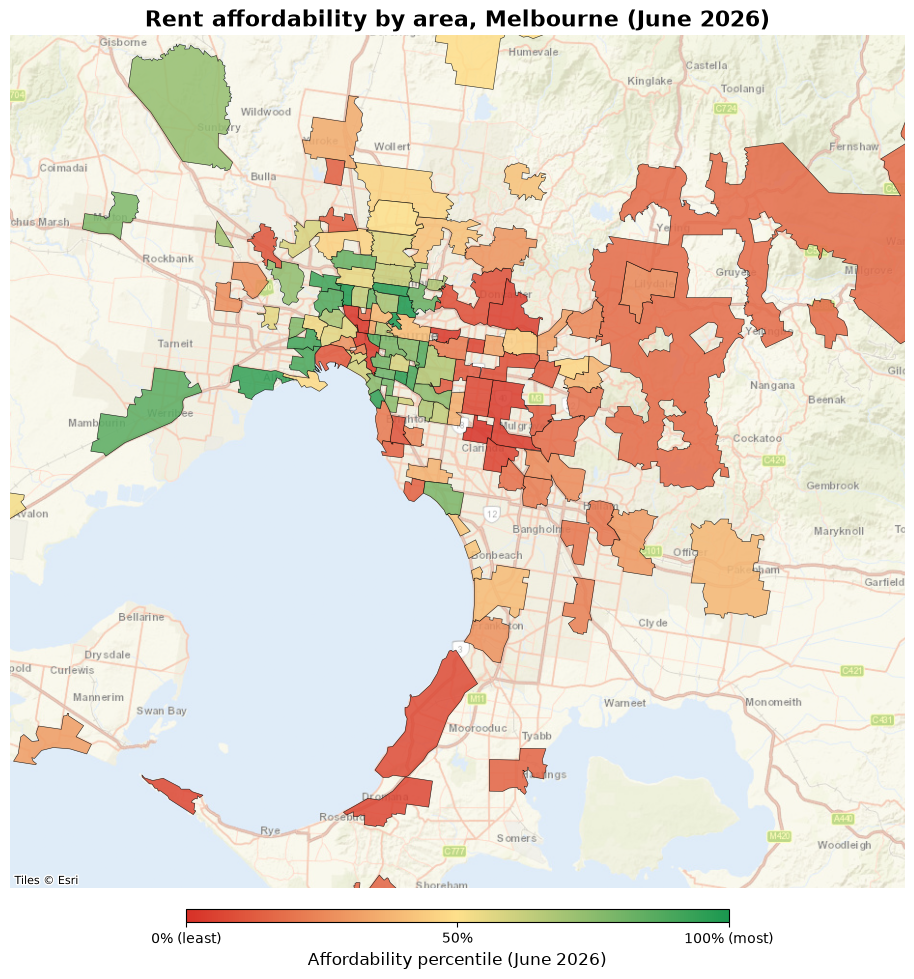

In [19]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from shapely.geometry import box

try:
    import contextily as cx
except ImportError:
    cx = None

# --- Settings -------------------------------------------------------------

# Red = least affordable, yellow = middle, green = most affordable.
COLOURS = ["#d73027", "#fee08b", "#1a9850"]

BASE_TILES = (
    "https://server.arcgisonline.com/ArcGIS/rest/services/"
    "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
)
USE_BASEMAP = True      # needs contextily and an internet connection
BASEMAP_ALPHA = 0.5     # 0 = invisible, 1 = fully opaque
FILL_OPACITY = 0.85     # how solid the coloured areas are
SIMPLIFY_METRES = 150   # shrinks shapes; lower = more detailed borders
FIG_WIDTH = 14          # inches
DPI = 200

# --- Map data -------------------------------------------------------------

# Victorian suburb polygons only, in metres (EPSG:3857) to match the tiles.
shapes = gpd.read_file(SHAPE_FILE)
shapes = shapes[shapes[SHAPE_STATE_COL] == "Victoria"]
shapes = shapes[[SHAPE_NAME_COL, "geometry"]]
shapes = shapes[~(shapes.geometry.isna() | shapes.geometry.is_empty)]
shapes = shapes.to_crs(epsg=3857)

# Attach each rent area's suburbs (rent_map, section 6) to their polygons.
area_shapes = gpd.GeoDataFrame(
    rent_map.merge(
        shapes, left_on=MAP_SUBURB_COL, right_on=SHAPE_NAME_COL, how="left"
    ),
    geometry="geometry",
    crs=shapes.crs,
)

# Every mapped suburb needs a polygon, or it would silently drop out.
no_shape = area_shapes.loc[
    area_shapes.geometry.isna(), MAP_SUBURB_COL
].tolist()
assert not no_shape, f"No polygon for suburbs: {no_shape}"

# Merge each rent area's suburbs into one shape.
area_shapes = (
    area_shapes[[RENT_AREA_COL, "geometry"]]
    .dissolve(by=RENT_AREA_COL)
    .reset_index()
)
area_shapes["geometry"] = area_shapes.simplify(
    SIMPLIFY_METRES, preserve_topology=True
)

map_data = area_shapes.merge(export, on=RENT_AREA_COL, how="left")
assert len(map_data) == len(areas), "Not every rent area has a shape"
assert map_data["rent_to_income_2026"].notna().all(), "Missing affordability"

# Light grey backdrop of every Victorian suburb, for areas with no rent data.
backdrop = shapes.copy()
backdrop["geometry"] = backdrop.simplify(
    SIMPLIFY_METRES * 2, preserve_topology=True
)

# --- Colour scale ---------------------------------------------------------

cmap = LinearSegmentedColormap.from_list("affordability", COLOURS)
norm = Normalize(vmin=0, vmax=1)

# --- Drawing function -----------------------------------------------------


def draw_map(extent, path, title):
    """Draw the affordability map for an (minx, miny, maxx, maxy) extent."""
    minx, miny, maxx, maxy = extent
    pad = 0.03 * max(maxx - minx, maxy - miny)
    minx, miny, maxx, maxy = minx - pad, miny - pad, maxx + pad, maxy + pad

    fig, ax = plt.subplots(
        figsize=(FIG_WIDTH, FIG_WIDTH * (maxy - miny) / (maxx - minx))
    )
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)

    # Street map background (fades towards white via alpha).
    basemap_ok = False
    if USE_BASEMAP and cx is not None:
        try:
            cx.add_basemap(
                ax, source=BASE_TILES, crs=map_data.crs,
                alpha=BASEMAP_ALPHA, attribution="Tiles © Esri",
            )
            basemap_ok = True
        except Exception as err:  # offline, blocked tiles, etc.
            print(f"Basemap skipped: {err}")

    if not basemap_ok:
        backdrop.plot(
            ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2
        )

    map_data.plot(
        column="affordability_percentile_2026",
        cmap=cmap, norm=norm,
        edgecolor="black", linewidth=0.4, alpha=FILL_OPACITY,
        ax=ax,
    )

    # add_basemap can change the limits, so set them again.
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ax.set_axis_off()
    ax.set_title(title, fontsize=16, fontweight="bold")

    cbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap), ax=ax,
        orientation="horizontal", shrink=0.5, aspect=40, pad=0.02,
    )
    cbar.set_ticks([0, 0.5, 1])
    cbar.set_ticklabels(["0% (least)", "50%", "100% (most)"])
    cbar.set_label("Affordability percentile (June 2026)", fontsize=12)

    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()


# --- Output ---------------------------------------------------------------

# Greater Melbourne, where most of the rent areas are.
melbourne_extent = gpd.GeoSeries(
    [box(144.5, -38.4, 145.7, -37.5)], crs=4326
).to_crs(epsg=3857).total_bounds
draw_map(
    melbourne_extent,
    MELBOURNE_IMAGE_FILE,
    "Rent affordability by area, Melbourne (June 2026)",
)